# Observatorio Ciudadano de Contratación Pública (SECOP II)
### Inteligencia Artificial y Datos Abiertos para Explorar Contratos Estatales, Consultar la Ley y Anticipar Prórrogas

---

## El Propósito del Proyecto
En Colombia, la contratación pública mueve una parte esencial del presupuesto del Estado. Aunque toda la información se publica a diario como datos abiertos en **SECOP II**, analizar millones de registros y cruzarlos con la legislación vigente sigue siendo una barrera enorme para ciudadanos, periodistas de investigación, veedurías y equipos de control interno.

Este proyecto nace para cerrar esa brecha a través de dos herramientas prácticas conectadas a una misma fuente de datos reales:

1. **Asistente de Consulta Ciudadana (RAG + SQL):** Permite hacer preguntas en lenguaje cotidiano y obtener respuestas que combinan cifras reales de contratos con los artículos exactos de la ley colombiana, citando siempre de dónde sale cada dato.
2. **Modelo Predictivo de Riesgo de Prórrogas:** Analiza las condiciones iniciales con las que se firma un contrato para estimar la probabilidad de que termine necesitando más tiempo del planeado (`dias_adicionados > 0`), ayudando a priorizar qué procesos merecen seguimiento preventivo.

> ⚠️ **Nota sobre el uso responsable:** Este observatorio identifica patrones estadísticos para orientar la revisión humana. Una prórroga o una alerta no equivale a una irregularidad ni reemplaza una auditoría oficial; cada caso debe contrastarse directamente en su expediente público mediante el enlace `urlproceso`.

> 📜 **Fuente y licencia de los datos:** Construido sobre datos abiertos de *«SECOP II – Contratos Electrónicos»* (Colombia Compra Eficiente, `datos.gov.co`) bajo licencia **CC BY-SA 4.0**. Proyecto independiente sin afiliación institucional.

--- 
## Punto de Partida: Preparación del Entorno
Antes de conectarnos a las fuentes oficiales, preparamos las rutas del proyecto, cargamos las credenciales de forma privada desde variables de entorno (`.env`) y definimos los parámetros base de nuestra consulta para que cualquier persona pueda reproducir el análisis.

In [22]:
# Recarga automática de módulos en src/observatorio/ al editar archivos .py
%load_ext autoreload
%autoreload 2

import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Asegurar que `src/` esté en sys.path incluso si se abre desde `notebooks/`
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from observatorio.config import (
    CLEAN_CSV_PATH,
    RANDOM_SEED,
    RAW_CSV_PATH,
    RAW_METADATA_PATH,
    SECOP_DEPARTAMENTO,
    SECOP_FECHA_FIN,
    SECOP_FECHA_INICIO,
    SQLITE_DB_PATH,
)
from observatorio.data.ingestion import COLUMNAS_SELECCIONADAS, descargar_subconjunto_secop
from observatorio.data.cleaning import (
    generar_resumen_validacion,
    limpiar_contratos_secop,
    obtener_diccionario_columnas,
)
from observatorio.data.database import ejecutar_consulta_segura, guardar_en_sqlite

np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

print("Entorno configurado correctamente.")
print(f"Departamento objetivo : {SECOP_DEPARTAMENTO}")
print(f"Rango de fechas       : {SECOP_FECHA_INICIO}  -->  {SECOP_FECHA_FIN}")
print(f"Ruta CSV Original     : {RAW_CSV_PATH}")
print(f"Ruta CSV Limpio       : {CLEAN_CSV_PATH}")
print(f"Ruta Base SQLite      : {SQLITE_DB_PATH}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Entorno configurado correctamente.
Departamento objetivo : Valle del Cauca
Rango de fechas       : 2023-01-01T00:00:00  -->  2026-10-31T23:59:59
Ruta CSV Original     : /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/data/raw/secop_contratos_original.csv
Ruta CSV Limpio       : /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/data/processed/secop_contratos_limpio.csv
Ruta Base SQLite      : /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/data/processed/secop_contratos.sqlite


---
# PARTE 1: De los Datos Abiertos a una Base Confiable (SECOP II)

## 1.1 Conexión Directa con Datos Abiertos Colombia
En lugar de trabajar con archivos estáticos descargados a mano, consultamos directamente la API oficial de **Datos Abiertos (`datos.gov.co`)**. Acotamos la descarga a un departamento y una ventana de tiempo concreta, registrando la fecha exacta de corte (ya que SECOP II cambia todos los días) y guardando una copia intacta del archivo original (`secop_contratos_original.csv`) como respaldo para auditoría.

In [23]:
# Cambia FORZAR_DESCARGA = True cuando quieras volver a consultar la API de datos.gov.co
FORZAR_DESCARGA = False
MAX_REGISTROS_DESCARGA = (
    50000  # Ajustable entre 20.000 y 100.000 según alcance (Sección 3)
)

if RAW_CSV_PATH.exists() and RAW_METADATA_PATH.exists() and not FORZAR_DESCARGA:
    print(f"📂 Cargando CSV original existente desde: {RAW_CSV_PATH}")
    df_raw = pd.read_csv(RAW_CSV_PATH, low_memory=False)
    metadatos_descarga = json.loads(RAW_METADATA_PATH.read_text(encoding="utf-8"))
else:
    print("🌐 Descargando subconjunto desde la API Socrata (datos.gov.co)...")
    df_raw, metadatos_descarga = descargar_subconjunto_secop(
        departamento=SECOP_DEPARTAMENTO,
        fecha_inicio=SECOP_FECHA_INICIO,
        fecha_fin=SECOP_FECHA_FIN,
        batch_size=10000,
        max_records=MAX_REGISTROS_DESCARGA,
        guardar_csv=True,
        ruta_csv=RAW_CSV_PATH,
        ruta_metadatos=RAW_METADATA_PATH,
    )
    print(f"✅ CSV original guardado en: {RAW_CSV_PATH}")

print("\n📋 Metadatos de trazabilidad de la descarga:")
for k, v in metadatos_descarga.items():
    if k != "columnas_descargadas":
        print(f"  - {k}: {v}")

print(
    f"\n🔎 Vista previa del CSV Original ({df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas):"
)
display(df_raw.head(5))

📂 Cargando CSV original existente desde: /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/data/raw/secop_contratos_original.csv

📋 Metadatos de trazabilidad de la descarga:
  - fecha_consulta_utc: 2026-10-30T06:00:29.008538+00:00
  - departamento: Valle del Cauca
  - fecha_inicio: 2023-01-01T00:00:00
  - fecha_fin: 2026-10-31T23:59:59
  - total_registros_descargados: 50000
  - dataset_id: jbjy-vk9h
  - ruta_csv_original: /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/data/raw/secop_contratos_original.csv

🔎 Vista previa del CSV Original (50,000 filas x 25 columnas):


,id_contrato,nombre_entidad,departamento,ciudad,sector,rama,orden,estado_contrato,tipo_de_contrato,modalidad_de_contratacion,fecha_de_firma,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,valor_del_contrato,dias_adicionados,es_pyme,es_grupo,habilita_pago_adelantado,origen_de_los_recursos,codigo_de_categoria_principal,tipodocproveedor,proveedor_adjudicado,descripcion_del_proceso,objeto_del_contrato,urlproceso
0,CO1.PCCNTR.10000004,DEPARTAMENTO DEL VALLE DEL CAUCA-SECRETARIA DE GESTION DEL RIESGO DE DESASTRES,Valle del Cauca,Cali,"Vivienda, Ciudad y Territorio",Ejecutivo,Territorial,En ejecución,Prestación de servicios,Contratación directa,2026-09-28T17:58:34.043,2026-09-29T05:00:00.000,2026-12-31T23:00:00.000,10000000.0,0,Si,No,No,Distribuido,UNSPECIFIED,Cédula de Ciudadanía,Yanneth Henao Ledesma,PRESTAR LOS SERVICIOS DE APOYO A LA GESTIÓN EN LA ACTIVIDAD ORIENTAR EN LA F...,PRESTAR LOS SERVICIOS DE APOYO A LA GESTIÓN EN LA ACTIVIDAD ORIENTAR EN LA F...,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...
1,CO1.PCCNTR.10000013,DEPARTAMENTO DEL VALLE DEL CAUCA - OFICINA PARA LA TRANSPARENCIA DE LA GESTI...,Valle del Cauca,Cali,Servicio Público,Ejecutivo,Territorial,En ejecución,Prestación de servicios,Contratación directa,2026-09-28T15:08:16.759,2026-09-29T08:00:00.000,2026-10-31T23:59:00.000,15400000.0,0,No,No,No,Distribuido,UNSPECIFIED,Cédula de Ciudadanía,ALIRIA DEL CARMEN GONALEZ VALENCIA,PRESTACIÓN DE SERVICIOS PROFESIONALES COMO ADMINISTRADOR DE EMPRESAS; MAGIST...,PRESTACIÓN DE SERVICIOS PROFESIONALES COMO ADMINISTRADOR DE EMPRESAS; MAGIST...,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...
2,CO1.PCCNTR.10000018,ALCALDIA MUNICIPIO DE JAMUNDI,Valle del Cauca,Jamundí,No aplica/No pertenece,Ejecutivo,Territorial,Modificado,Prestación de servicios,Contratación directa,2026-09-28T13:35:37.860,2026-09-28T14:00:00.000,2026-12-31T23:00:00.000,12000000.0,0,No,No,No,Distribuido,UNSPECIFIED,Cédula de Ciudadanía,Andres Jose urbano Rodriguez,PRESTACION DE SERVICIOS DE APOYO A LA\nGESTION EN LA SECRETARÍA DE HACIENDA;...,PRESTACION DE SERVICIOS DE APOYO A LA\nGESTION EN LA SECRETARÍA DE HACIENDA;...,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...
3,CO1.PCCNTR.10000020,DEPARTAMENTO DEL VALLE DEL CAUCA-SECRETARIA DE GESTION DEL RIESGO DE DESASTRES,Valle del Cauca,Cali,"Vivienda, Ciudad y Territorio",Ejecutivo,Territorial,En ejecución,Prestación de servicios,Contratación directa,2026-09-28T16:29:44.152,2026-09-29T05:00:00.000,2026-12-31T23:00:00.000,14000000.0,0,No,No,No,Distribuido,UNSPECIFIED,Cédula de Ciudadanía,Luz Mary Ramirez Marin,PRESTAR LOS SERVICIOS DE APOYO A LA GESTIÓN COMO TECNOLOGA EN PREVENCION Y A...,PRESTAR LOS SERVICIOS DE APOYO A LA GESTIÓN COMO TECNOLOGA EN PREVENCION Y A...,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...
4,CO1.PCCNTR.10000032,DEPARTAMENTO DEL VALLE DEL CAUCA-SECRETARIA DE GESTION DEL RIESGO DE DESASTRES,Valle del Cauca,Cali,"Vivienda, Ciudad y Territorio",Ejecutivo,Territorial,En ejecución,Prestación de servicios,Contratación directa,2026-09-28T16:16:44.601,2026-09-29T05:00:00.000,2026-12-31T23:00:00.000,24000000.0,0,No,No,No,Distribuido,UNSPECIFIED,Cédula de Ciudadanía,STEPHANY SALAS BASANTE,PRESTAR LOS SERVICIOS PROFESIONALES COMO ABOGADA ESPECIALISTA Y MAGISTER EN ...,PRESTAR LOS SERVICIOS PROFESIONALES COMO ABOGADA ESPECIALISTA Y MAGISTER EN ...,{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...


## 1.2 Curaduría de Datos y Protección de Privacidad
Los registros administrativos crudos suelen incluir ruido, formatos inconsistentes y datos sensibles. En este paso preparamos una versión limpia (`secop_contratos_limpio.csv`) aplicando tres criterios:
- **Privacidad por diseño:** Excluimos documentos de identidad, direcciones, cuentas bancarias y anonimizamos los nombres de contratistas cuando corresponden a personas naturales, manteniendo visibles únicamente las razones sociales de empresas (`NIT`).
- **Calidad y consistencia:** Eliminamos registros duplicados por `id_contrato`, estandarizamos fechas y valores monetarios, y extraemos el enlace directo al proceso original.
- **Contraste transparente:** Comparamos el archivo original frente al archivo limpio para verificar qué cambió exactamente durante el proceso.

In [24]:
# Ejecutar limpieza y guardar el archivo CSV limpio en data/processed/secop_contratos_limpio.csv
df_clean = limpiar_contratos_secop(
    df_raw,
    guardar_csv=True,
    ruta_csv_limpio=CLEAN_CSV_PATH,
)

print(f"✅ CSV limpio guardado en: {CLEAN_CSV_PATH}")

# 1. Tabla comparativa de validación (CSV Original vs CSV Limpio)
print("\n📊 Tabla de Validación Comparativa (Original vs. Limpio):")
df_resumen_validacion = generar_resumen_validacion(df_raw, df_clean)
display(df_resumen_validacion)

# 2. Verificación visual de la transformación en columnas clave
cols_comparacion = [
    "id_contrato",
    "fecha_de_firma",
    "valor_del_contrato",
    "dias_adicionados",
    "tipodocproveedor",
    "proveedor_adjudicado",
    "urlproceso",
]
cols_presentes = [c for c in cols_comparacion if c in df_clean.columns]
print("\n🔎 Muestra del CSV Limpio en columnas auditadas:")
display(df_clean[cols_presentes].head(5))

# 3. Diccionario de las 25 columnas seleccionadas
print("\n📖 Diccionario de Columnas del Proyecto:")
display(obtener_diccionario_columnas())

✅ CSV limpio guardado en: /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/data/processed/secop_contratos_limpio.csv

📊 Tabla de Validación Comparativa (Original vs. Limpio):


,Métrica de Validación,CSV Original (Raw),CSV Limpio (Processed)
0,Total de filas (registros),50000,50000
1,Total de columnas,25,25
2,Duplicados por id_contrato,0,0
3,Proveedores Persona Natural anonimizados,Sin anonimizar (0),46930
4,Nulos en valor_del_contrato,0,0
5,Nulos en dias_adicionados,0,0



🔎 Muestra del CSV Limpio en columnas auditadas:


,id_contrato,fecha_de_firma,valor_del_contrato,dias_adicionados,tipodocproveedor,proveedor_adjudicado,urlproceso
0,CO1.PCCNTR.10000004,2026-09-28,10000000.0,0,Cédula de Ciudadanía,PERSONA NATURAL (ANONIMIZADO),{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...
1,CO1.PCCNTR.10000013,2026-09-28,15400000.0,0,Cédula de Ciudadanía,PERSONA NATURAL (ANONIMIZADO),{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...
2,CO1.PCCNTR.10000018,2026-09-28,12000000.0,0,Cédula de Ciudadanía,PERSONA NATURAL (ANONIMIZADO),{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...
3,CO1.PCCNTR.10000020,2026-09-28,14000000.0,0,Cédula de Ciudadanía,PERSONA NATURAL (ANONIMIZADO),{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...
4,CO1.PCCNTR.10000032,2026-09-28,24000000.0,0,Cédula de Ciudadanía,PERSONA NATURAL (ANONIMIZADO),{'url': 'https://community.secop.gov.co/Public/Tendering/OpportunityDetail/I...



📖 Diccionario de Columnas del Proyecto:


,columna,tipo,uso
0,id_contrato,Texto (PK),Identificador único del contrato electrónico en SECOP II.
1,nombre_entidad,Categórica,Nombre oficial de la entidad estatal contratante.
2,departamento,Categórica,Departamento de ejecución o registro de la entidad.
3,ciudad,Categórica,Municipio o ciudad asociada a la entidad contratante.
4,sector,Categórica,Sector administrativo al que pertenece la entidad.
5,rama,Categórica,"Rama del poder público (Ejecutiva, Legislativa, Judicial, etc.)."
6,orden,Categórica,"Nivel administrativo (Nacional, Territorial)."
7,estado_contrato,Categórica,"Estado actual del contrato (solo para consultas SQL, excluido de ML por leak..."
8,tipo_de_contrato,Categórica,"Tipología contractual (Prestación de servicios, Obra, Suministro, etc.)."
9,modalidad_de_contratacion,Categórica,"Modalidad legal de selección (Contratación directa, Licitación, Mínima cuant..."


## 1.3 Construcción de la Base de Datos de Consulta Rápida (`SQLite`)
Con el dataset curado y validado, lo estructuramos dentro de una base de datos relacional local (`secop_contratos.sqlite`). Esta base sirve como fuente única tanto para responder preguntas sobre cifras en el asistente conversacional como para alimentar el entrenamiento del modelo predictivo.

In [25]:
# Volcar el DataFrame limpio en SQLite y crear índices
total_en_sqlite = guardar_en_sqlite(df_clean, db_path=SQLITE_DB_PATH)

assert total_en_sqlite == len(
    df_clean
), f"Discrepancia de conteo: SQLite ({total_en_sqlite}) != CSV Limpio ({len(df_clean)})"
print(f"✅ Base de datos SQLite creada e indexada en: {SQLITE_DB_PATH}")
print(
    f"✔️ Conteo verificado: {total_en_sqlite:,} contratos en SQLite == {len(df_clean):,} en CSV limpio."
)

# Prueba rápida del ejecutor SQL en modo solo lectura (modo seguro)
consulta_prueba = """
SELECT modalidad_de_contratacion,
       COUNT(*) AS total_contratos,
       ROUND(AVG(valor_del_contrato), 0) AS valor_promedio_cop
FROM contratos
GROUP BY modalidad_de_contratacion
ORDER BY total_contratos DESC
"""
df_sql_test, sql_ejecutado = ejecutar_consulta_segura(
    consulta_prueba, db_path=SQLITE_DB_PATH
)
print(f"\n🔒 SQL ejecutado en modo solo lectura:\n{sql_ejecutado}")
display(df_sql_test)

✅ Base de datos SQLite creada e indexada en: /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/data/processed/secop_contratos.sqlite
✔️ Conteo verificado: 50,000 contratos en SQLite == 50,000 en CSV limpio.

🔒 SQL ejecutado en modo solo lectura:
SELECT modalidad_de_contratacion,
       COUNT(*) AS total_contratos,
       ROUND(AVG(valor_del_contrato), 0) AS valor_promedio_cop
FROM contratos
GROUP BY modalidad_de_contratacion
ORDER BY total_contratos DESC LIMIT 100


,modalidad_de_contratacion,total_contratos,valor_promedio_cop
0,Contratación directa,46449,3.127772e+07
1,Contratación régimen especial,2206,2.023820e+08
2,Mínima cuantía,786,3.485596e+07
3,Contratación Directa (con ofertas),159,1.342916e+09
4,Contratación régimen especial (con ofertas),137,7.665481e+08
5,Selección Abreviada de Menor Cuantía,133,3.886737e+08
6,Selección abreviada subasta inversa,47,1.237557e+09
7,Licitación pública,41,7.309987e+09
8,Concurso de méritos abierto,24,8.685264e+08
9,Licitación pública Obra Publica,13,4.305837e+09


---
# PARTE 2: Asistente Híbrido de Contratación Pública (RAG Normativo + SQL)

## 2.1 Construyendo la Biblioteca Jurídica y Técnica
Un ciudadano no solo necesita saber *cuánto* se contrató, sino *qué dice la norma* al respecto. Aquí reunimos y estructuramos el marco regulatorio esencial de la contratación pública en Colombia (**Ley 80 de 1993**, **Ley 1150 de 2007**, **Decreto 1082 de 2015**, **Circular Externa Única** y los manuales/diccionarios de **Colombia Compra Eficiente**), organizando cada documento con su fuente, fecha y artículo para poder citarlo con precisión.

In [37]:
# TODO: Lectura de archivos Markdown del corpus normativo y extracción/asignación de metadatos
from observatorio.config import CORPUS_DIR, CORPUS_MARKDOWN_DIR
from observatorio.rag.chunking import ProcesadorCorpusMarkdown

procesador = ProcesadorCorpusMarkdown()

# Conversor de PDF a Markdown (convierte todos los PDFs en el directorio `CORPUS_DIR` a Markdown y los guarda en `CORPUS_MARKDOWN_DIR`)
corpus = procesador.procesar_directorio_corpus(
    directorio_raiz=CORPUS_DIR,
    directorio_salida_md=CORPUS_MARKDOWN_DIR,
)

## 2.2 Cómo Dividir la Ley sin Perder el Contexto (Chunking)
Si partimos un artículo de ley en pedazos demasiado pequeños, se pierde el sentido jurídico; si dejamos bloques demasiado largos, la búsqueda pierde precisión. En esta sección ponemos a prueba distintas estrategias de fragmentación respetando la estructura por artículos para elegir el equilibrio ideal.

In [38]:
# TODO: Configurar al menos 3 tamaños en RecursiveCharacterTextSplitter
# TODO: Construir tabla comparativa de métricas de chunking y seleccionar el tamaño definitivo
from observatorio.rag.chunking import EvaluadorChunking, FragmentadorNormativo

evaluador = EvaluadorChunking()
fragmentador = FragmentadorNormativo()

# 1. Comparación de fragmentación recursiva por tamaños (al menos 3 configuraciones)
df_comparacion_recursivo = evaluador.comparar_recursivo(corpus)
print("📊 Comparación de fragmentación recursiva:")
display(df_comparacion_recursivo)

# 2. Comparación de fragmentación semántica por percentiles (usar_local=True para evitar consumo de API de Gemini)
df_comparacion_semantico = evaluador.comparar_semantico(
    corpus[:3], percentiles_a_probar=[90, 95, 99], usar_local=True
)
print("📊 Comparación de fragmentación semántica:")
display(df_comparacion_semantico)

# 3. Fragmentación definitiva del corpus con la estrategia seleccionada (recursiva equilibrada)
fragmentos = fragmentador.fragmentar_corpus(
    corpus, metodo="recursivo", chunk_size=1000, chunk_overlap=150
)
print(f"📦 Fragmentos generados: {len(fragmentos):,}")

📊 Comparación de fragmentación recursiva:


,chunk_size,chunk_overlap,num_fragmentos,longitud_media,longitud_minima,longitud_maxima
0,600,100,7276,448.8,2,599
1,1000,150,4256,775.1,2,999
2,1600,250,2696,1236.9,4,1599


📊 Comparación de fragmentación semántica:


,breakpoint_percentile,num_fragmentos,longitud_media,longitud_minima,longitud_maxima
0,90,18,2997.7,434,10632
1,95,12,4497.5,1198,11995
2,99,6,8997.0,4020,13974


📦 Fragmentos generados: 4,256


## 2.3 Indexación Semántica en la Nube (`Qdrant Cloud` + `Gemini Embeddings`)
Transformamos cada fragmento normativo en representaciones vectoriales utilizando **Gemini Embedding 2** y los almacenamos en una base vectorial en la nube (**Qdrant Cloud**). De esta forma, el sistema puede encontrar el artículo pertinente aunque el usuario formule su pregunta con palabras cotidianas muy distintas al texto legal.

In [39]:
# TODO: Inicializar cliente Qdrant Cloud y crear colección con VectorParams(size=768, distance=Distance.COSINE)
# TODO: Generar embeddings por lotes con Gemini Embedding 2, guardar respaldo local y hacer upsert en Qdrant
import importlib
import observatorio.rag.vectorstore as vs

importlib.reload(vs)
from observatorio.rag.vectorstore import IndexadorQdrant, EMBEDDINGS_BACKUP_PATH

# Inicializar indexador (puedes omitir usar_local para intentar con Gemini y fallback automático a local)
indexador = IndexadorQdrant(usar_local=True)

total_en_qdrant = indexador.indexar_fragmentos(fragmentos)
print(f"✅ Total de puntos vectoriales indexados en Qdrant: {total_en_qdrant:,}")

assert total_en_qdrant == len(
    fragmentos
), f"Discrepancia de conteo: Qdrant ({total_en_qdrant}) != Fragmentos ({len(fragmentos)})"
print(
    f"✔️ Verificado: {total_en_qdrant:,} puntos en Qdrant == {len(fragmentos):,} fragmentos"
)
print(f"Respaldo de vectores: {EMBEDDINGS_BACKUP_PATH}")

🔍 Inicializando IndexadorQdrant en colección 'normativa_contratacion'.
   Qdrant URL: https://c0be2581-0382-42bc-82fe-47333af56596.us-east-2-0.aws.cloud.qdrant.io
   Modo inicial de embeddings: LOCAL (sentence-transformers/paraphrase-multilingual-mpnet-base-v2)
La colección 'normativa_contratacion' ya se encuentra activa en Qdrant.
📂 Respaldo local detectado: 4,254 vectores cargados desde embeddings_normativa.parquet.
✅ Todos los 4,256 fragmentos ya cuentan con embeddings en disco.
☁️ Subiendo 4,256 puntos a Qdrant Cloud en colección 'normativa_contratacion'...
✅ Indexación finalizada: 4,256 puntos activos en Qdrant Cloud.
✅ Total de puntos vectoriales indexados en Qdrant: 4,256
✔️ Verificado: 4,256 puntos en Qdrant == 4,256 fragmentos
Respaldo de vectores: /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/data/processed/embeddings_normativa.parquet


## 2.4 Conectando las Cifras (`SQL`) con las Normas (`RAG`)
Aquí unimos ambos mundos: diseñamos el buscador semántico sobre la normativa y el motor de consultas de solo lectura sobre la base de contratos. Así, el asistente puede decidir cuándo responder con estadísticas de la base de datos, cuándo citar un artículo de ley o cuándo combinar ambos en una sola respuesta.

In [40]:
# TODO: Definir función de recuperación semántica Top-k sobre Qdrant con filtro opcional por documento
# TODO: Definir herramienta de consulta SQL de solo lectura (validación de SELECT único y límite de filas)

df_resultados = indexador.buscar_similares(
    "¿Cuál es la duración máxima permitida para un contrato de obras públicas según la ley?",
    top_k=3,
)
display(df_resultados)

# Con filtro por documento
display(
    indexador.buscar_similares(
        "principios de la contratación estatal",
        top_k=3,
        filtro_documento="Ley 80 de 1993",
    )
)

display(
    indexador.buscar_similares(
        "cuáles son los principios de la contratación pública",
        top_k=3,
        filtro_documento="Ley 1150 de 2007",
    )
)

# 1. Consulta SQL válida (ej: top 5 modalidades con mayor cuantía)
sql_ejemplo = """
SELECT modalidad_de_contratacion, COUNT(*) AS total_contratos, ROUND(SUM(valor_del_contrato), 2) AS valor_total
FROM contratos
GROUP BY modalidad_de_contratacion
ORDER BY valor_total DESC
"""
df_cifras, sql_ejecutado = ejecutar_consulta_segura(sql_ejemplo)
print(f"SQL ejecutado con seguridad: {sql_ejecutado}")
display(df_cifras)
# 2. Demostración de protección (bloquea inyecciones o mutaciones)
try:
    ejecutar_consulta_segura("DELETE FROM contratos WHERE valor_del_contrato = 0")
except ValueError as e:
    print(f"🛡️ Bloqueo de seguridad verificado: {e}")

📦 Descargando/cargando modelo local 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2'...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✅ Modelo local 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2' listo en memoria.


,rank,score_coseno,documento,articulo,tipo_fuente,fecha,texto
0,1,0.6953,Decreto 1082 de 2015,Artículo 34 d,Decreto Reglamentario,26 de mayo de 2015,"7. En cumplimiento de lo previsto en el artículo 34 de la Ley 1508 de 2012, ..."
1,2,0.6549,Decreto 1082 de 2015,Artículo 2,Decreto Reglamentario,26 de mayo de 2015,Capacidad Residual del Proceso de Contratación = Presupuesto oﬁcial estimado...
2,3,0.6502,Decreto 1082 de 2015,Artículo 2,Decreto Reglamentario,26 de mayo de 2015,ARTÍCULO 2.2.1.1.1.6.4. Capacidad Residual. El interesado en celebrar contra...


,rank,score_coseno,documento,articulo,tipo_fuente,fecha,texto
0,1,0.0752,Ley 80 de 1993,Artículo 224 d,Ley de la República,28 de octubre de 1993,Notas de Vigencia\nJurisprudencia Vigencia\n\n3o. <Numeral modificado por el...
1,2,0.0601,Ley 80 de 1993,Artículo 1 d,Ley de la República,28 de octubre de 1993,de selección se llamará concurso y se efectuará también mediante invitación ...
2,3,0.0505,Ley 80 de 1993,Artículo 1 d,Ley de la República,28 de octubre de 1993,Notas de Vigencia\n\nPARÁGRAFO 3o. <Parágrafo adicionado por el artícu...


,rank,score_coseno,documento,articulo,tipo_fuente,fecha,texto
0,1,0.0512,Ley 1150 de 2007,Artículo 9,Ley de la República,16 de julio de 2007,ARTÍCULO 9o. DE LA ADJUDICACIÓN. En el evento previsto en el artículo 273 de...
1,2,0.0459,Ley 1150 de 2007,Artículo 2,Ley de la República,16 de julio de 2007,Para las entidades que tengan un presupuesto anual superior o igua...
2,3,0.0433,Ley 1150 de 2007,Artículo 54 d,Ley de la República,16 de julio de 2007,siguiente:> Corresponde a Ia modalidad prevista para Ia selección d...


SQL ejecutado con seguridad: SELECT modalidad_de_contratacion, COUNT(*) AS total_contratos, ROUND(SUM(valor_del_contrato), 2) AS valor_total
FROM contratos
GROUP BY modalidad_de_contratacion
ORDER BY valor_total DESC LIMIT 100


,modalidad_de_contratacion,total_contratos,valor_total
0,Contratación directa,46449,1.452819e+12
1,Contratación régimen especial,2206,4.464546e+11
2,Licitación pública,41,2.997095e+11
3,Contratación Directa (con ofertas),159,2.135236e+11
4,Contratación régimen especial (con ofertas),137,1.050171e+11
5,Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes,4,8.428415e+10
6,Selección abreviada subasta inversa,47,5.816516e+10
7,Licitación pública Obra Publica,13,5.597588e+10
8,Selección Abreviada de Menor Cuantía,133,5.169360e+10
9,Mínima cuantía,786,2.739679e+10


🛡️ Bloqueo de seguridad verificado: Operación bloqueada: solo se permiten consultas SELECT de lectura.


## 2.5 Poniendo a Prueba al Asistente: Precisión, Tiempos y Límites
Para asegurarnos de que el asistente sea confiable en escenarios reales, lo evaluamos con un banco de preguntas directas, preguntas en lenguaje coloquial, consultas que mezclan cifras con legislación y preguntas trampa sobre temas fuera del sistema (verificando que reconozca cuando no tiene la información en lugar de inventar respuestas).

In [41]:
# Evaluación automatizada del Asistente Híbrido sobre el banco de 12 preguntas de validación
from observatorio.rag.assistant import AsistenteHibrido
from observatorio.rag.evaluation import ejecutar_evaluacion_completa

# 1. Instanciar asistente en modo local
asistente = AsistenteHibrido(indexador_vectorial=indexador, usar_local=True)

# 2. Ejecutar protocolo de evaluación (protocolo estandarizado)
df_evaluacion, df_resumen = ejecutar_evaluacion_completa(asistente)

# 3. Métricas consolidadas (Acierto de enrutamiento, fuentes, alucinación y latencia)
print("📊 Resumen Global de Evaluación:")
display(df_resumen)

# 4. Tabla detallada por pregunta y categoría
print("\n🔎 Detalle de Evaluación por Pregunta:")
cols_ver = ["id", "categoria", "tipo_esperado", "tipo_obtenido", "acierto_tipo", "acierto_fuente", "score_max", "latencia_s", "sql_ejecutado", "fuentes_doc"]
display(df_evaluacion[cols_ver])

🤖 AsistenteHibrido inicializado en modo: 100% LOCAL (sin Gemini).
📊 Resumen Global de Evaluación:


,Métrica,Valor
0,Total de preguntas evaluadas,12
1,Precisión Clasificación de Intención (Router),91.7%
2,Tasa de Acierto en Fuentes / SQL,91.7%
3,Control de Alucinación (Rechazo Fuera de Alcance),100.0%
4,Latencia Promedio,0.133 s
5,Latencia Percentil 95 (P95),0.344 s



🔎 Detalle de Evaluación por Pregunta:


,id,categoria,tipo_esperado,tipo_obtenido,acierto_tipo,acierto_fuente,score_max,latencia_s,sql_ejecutado,fuentes_doc
0,EVAL-01,normativa_directa,normativa,normativa,True,True,0.7124,0.165,N/A,"MANUAL DE LA MODALIDAD DE SELECCIÓN DE MÍNIMA CUANTÍA, Guía para Adelantar e..."
1,EVAL-02,normativa_directa,normativa,normativa,True,True,0.6706,0.130,N/A,"MANUAL DE LA MODALIDAD DE SELECCIÓN DE MÍNIMA CUANTÍA, Decreto 1082 de 2015"
2,EVAL-03,normativa_directa,normativa,normativa,True,True,0.7995,0.130,N/A,"MANUAL DE LA MODALIDAD DE SELECCIÓN DE MÍNIMA CUANTÍA, Decreto 1082 de 2015"
3,EVAL-04,normativa_coloquial,normativa,normativa,True,True,0.6505,0.147,N/A,Decreto 1082 de 2015
4,EVAL-05,normativa_coloquial,normativa,normativa,True,True,0.5468,0.149,N/A,MANUAL DE LA MODALIDAD DE SELECCIÓN DE MÍNIMA CUANTÍA
5,EVAL-06,cuantitativa_sql,cuantitativa,cuantitativa,True,True,0.0000,0.127,"SELECT nombre_entidad, COUNT(*) AS total_contratos, ROUND(SUM(valor_del_cont...",N/A
6,EVAL-07,cuantitativa_sql,cuantitativa,cuantitativa,True,True,0.0000,0.021,"SELECT modalidad_de_contratacion, COUNT(*) AS total_contratos, ROUND(SUM(val...",N/A
7,EVAL-08,cuantitativa_sql,cuantitativa,cuantitativa,True,True,0.0000,0.014,"SELECT COUNT(*) AS total_con_adiciones, ROUND(AVG(dias_adicionados), 1) AS p...",N/A
8,EVAL-09,mixta,mixta,mixta,True,True,0.7066,0.260,"SELECT modalidad_de_contratacion, COUNT(*) AS total_contratos, ROUND(SUM(val...","MANUAL DE LA MODALIDAD DE SELECCIÓN DE MÍNIMA CUANTÍA, Decreto 1082 de 2015"
9,EVAL-10,mixta,mixta,normativa,False,False,0.6681,0.447,N/A,GUÍA PARA PROMOVER LA PARTICIPACIÓN DE LAS MIPYMES EN LOS PROCESOS DE COMPRA...


---
# PARTE 3: Modelo Predictivo de Riesgo de Prórroga en Contratos

## 3.1 Entendiendo el Problema: ¿Qué Contratos Terminan Pidiendo Más Plazo?
Cuando un contrato público sufre prórrogas (`dias_adicionados > 0`), suele reflejar retos de planeación, cuellos de botella en la ejecución o complejidades propias del sector. Antes de entrenar cualquier algoritmo, exploramos los datos para entender qué tan frecuentes son las prórrogas y cómo varían según el tipo de contrato, la modalidad de selección y el monto involucrado.

Contratos totales                  : 50,000
Contratos aptos para modelar       : 38,240  (plazo ya vencido)
Excluidos por estar aún en plazo   : 11,760
Tasa de prórroga en datos modelables: 11.94%


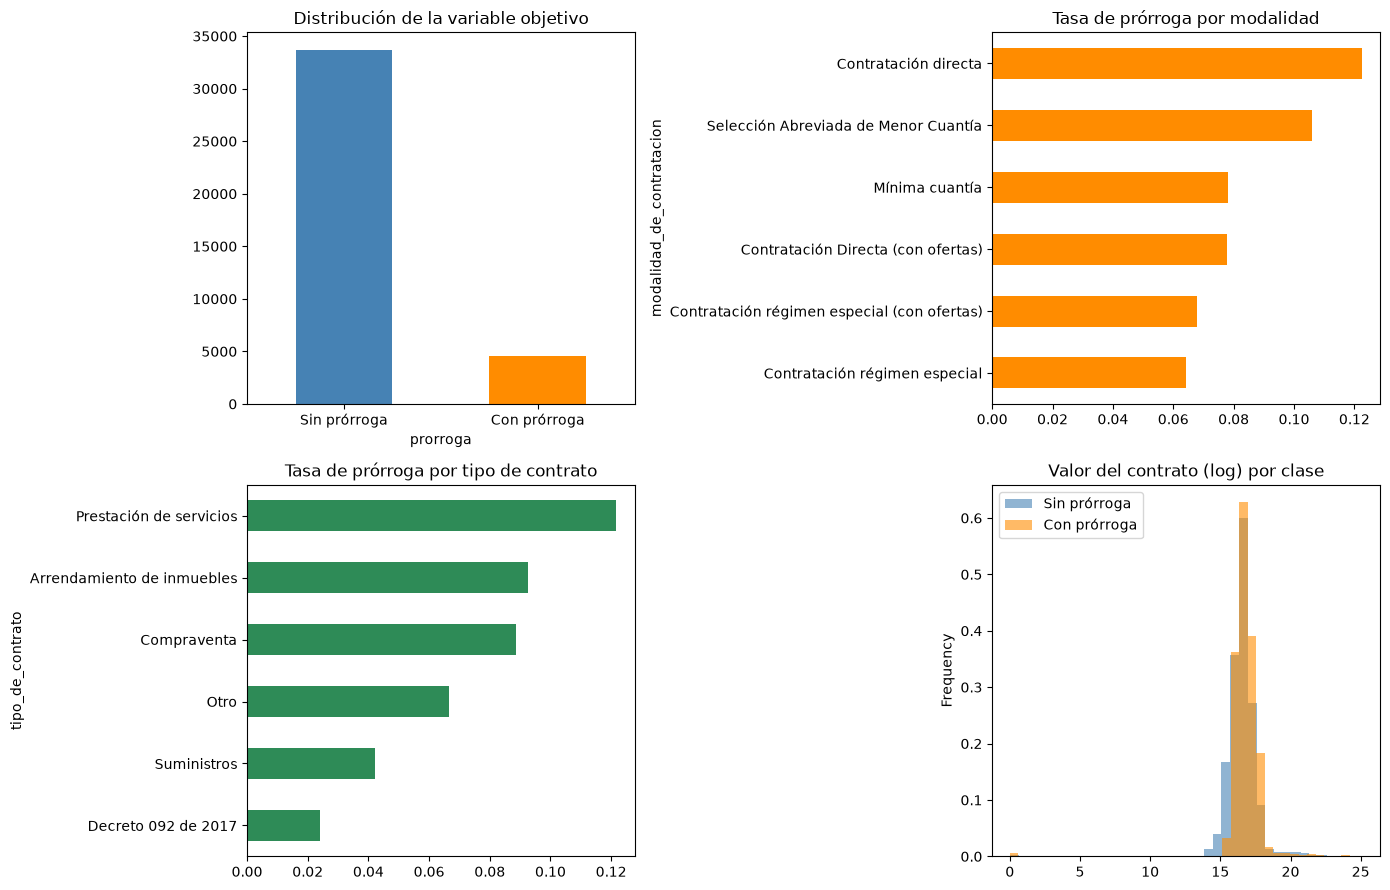

In [31]:
# Construcción y auditoría de la variable objetivo (dias_adicionados > 0)
import sqlite3
import matplotlib.pyplot as plt
from observatorio.ml.features import COLUMNA_OBJETIVO, construir_dataset_modelado

# 1. Cargar los contratos desde la base SQLite construida en la Parte 1
with sqlite3.connect(SQLITE_DB_PATH) as conn:
    df_contratos = pd.read_sql_query("SELECT * FROM contratos", conn)

# 2. Crear objetivo + variables derivadas y quitar contratos que aún no terminan su plazo
df_modelo = construir_dataset_modelado(df_contratos)

print(f"Contratos totales                  : {len(df_contratos):,}")
print(f"Contratos aptos para modelar       : {len(df_modelo):,}  (plazo ya vencido)")
print(f"Excluidos por estar aún en plazo   : {len(df_contratos) - len(df_modelo):,}")
print(f"Tasa de prórroga en datos modelables: {df_modelo[COLUMNA_OBJETIVO].mean():.2%}")

# 3. Gráficos exploratorios
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Distribución de clases
df_modelo[COLUMNA_OBJETIVO].map({0: "Sin prórroga", 1: "Con prórroga"}).value_counts().plot.bar(
    ax=axes[0, 0], color=["steelblue", "darkorange"], title="Distribución de la variable objetivo", rot=0)

# Tasa de prórroga por modalidad (solo modalidades con al menos 50 contratos)
tasa_modalidad = df_modelo.groupby("modalidad_de_contratacion")[COLUMNA_OBJETIVO].agg(["mean", "size"])
tasa_modalidad.query("size >= 50")["mean"].sort_values().plot.barh(
    ax=axes[0, 1], color="darkorange", title="Tasa de prórroga por modalidad")

# Tasa de prórroga por tipo de contrato
tasa_tipo = df_modelo.groupby("tipo_de_contrato")[COLUMNA_OBJETIVO].agg(["mean", "size"])
tasa_tipo.query("size >= 50")["mean"].sort_values().plot.barh(
    ax=axes[1, 0], color="seagreen", title="Tasa de prórroga por tipo de contrato")

# Valor del contrato en escala log según la clase
for clase, color in [(0, "steelblue"), (1, "darkorange")]:
    df_modelo.loc[df_modelo[COLUMNA_OBJETIVO] == clase, "valor_contrato_log"].plot.hist(
        ax=axes[1, 1], bins=40, alpha=0.6, density=True, color=color,
        label="Con prórroga" if clase else "Sin prórroga")
axes[1, 1].set_title("Valor del contrato (log) por clase")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 3.2 Regla de Oro: Usar Solo lo que se Sabe el Día de la Firma
Un error común al modelar datos públicos es incluir columnas que se actualizan meses después de firmado el contrato (como el estado de liquidación o los pagos acumulados), lo que produce modelos artificialmente perfectos pero inútiles en la vida real. Aquí seleccionamos exclusivamente las variables conocidas en el instante de la firma.

In [32]:
# Listas explícitas de variables conocidas el día de la firma (definidas en src/observatorio/ml/features.py)
from observatorio.ml.features import (
    FEATURES_CATEGORICAS_PERMITIDAS,
    FEATURES_NUMERICAS_PERMITIDAS,
    VARIABLES_EXCLUIDAS_LEAKAGE,
    verificar_ausencia_leakage,
)

FEATURES_MODELO = FEATURES_NUMERICAS_PERMITIDAS + FEATURES_CATEGORICAS_PERMITIDAS
print("Numéricas  :", FEATURES_NUMERICAS_PERMITIDAS)
print("Categóricas:", FEATURES_CATEGORICAS_PERMITIDAS)

# Auditoría de fuga: lanza error si alguna variable post-firma se coló en la lista
verificar_ausencia_leakage(FEATURES_MODELO)
print(f"\n✅ Sin data leakage. Variables excluidas a propósito: {sorted(VARIABLES_EXCLUIDAS_LEAKAGE)}")

# Nulos por variable: se imputan dentro del pipeline (mediana / 'DESCONOCIDO') en lugar de borrar filas
display(df_modelo[FEATURES_MODELO].isna().sum().to_frame("nulos").query("nulos > 0"))

Numéricas  : ['valor_contrato_log', 'mes_firma', 'anio_firma', 'duracion_planeada_dias']
Categóricas: ['tipo_de_contrato', 'modalidad_de_contratacion', 'sector', 'rama', 'orden', 'departamento', 'es_pyme', 'es_grupo', 'habilita_pago_adelantado', 'origen_de_los_recursos', 'segmento_unspsc']

✅ Sin data leakage. Variables excluidas a propósito: ['dias_adicionados', 'estado_contrato', 'fecha_fin_ejecucion', 'fecha_ini_ejecucion', 'liquidaci_n', 'prorroga', 'reversion', 'saldo_cdp', 'valor_amortizado', 'valor_de_pago_adelantado', 'valor_facturado', 'valor_pagado', 'valor_pendiente_de_pago']


,nulos
duracion_planeada_dias,23


## 3.3 Entrenar con el Pasado, Evaluar en el Futuro
Para simular cómo funcionaría esta herramienta en manos de una veeduría o una oficina de control interno, dividimos los contratos cronológicamente: entrenamos los modelos con el historial previo y los ponemos a prueba sobre los contratos más recientes.

In [33]:
# Partición temporal: el 80 % más antiguo para entrenar y el 20 % más reciente para probar
from observatorio.ml.pipeline import construir_preprocesador

# df_modelo ya viene ordenado por fecha_de_firma, así que basta con cortar por posición
indice_corte = int(len(df_modelo) * 0.8)
df_train = df_modelo.iloc[:indice_corte]
df_test = df_modelo.iloc[indice_corte:]

X_train, y_train = df_train[FEATURES_MODELO], df_train[COLUMNA_OBJETIVO]
X_test, y_test = df_test[FEATURES_MODELO], df_test[COLUMNA_OBJETIVO]

display(pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Contratos": [len(df_train), len(df_test)],
    "Desde": [df_train["fecha_de_firma"].min().date(), df_test["fecha_de_firma"].min().date()],
    "Hasta": [df_train["fecha_de_firma"].max().date(), df_test["fecha_de_firma"].max().date()],
    "% con prórroga": [y_train.mean() * 100, y_test.mean() * 100],
}).round(2))

# ColumnTransformer: imputación + escalado (numéricas) e imputación + One-Hot (categóricas).
# Va DENTRO de cada pipeline, por lo que se ajusta únicamente con X_train (sin fuga hacia el test).
preprocesador = construir_preprocesador()
print(f"Columnas tras el preprocesamiento: {preprocesador.fit(X_train).transform(X_train.head()).shape[1]}")

,Conjunto,Contratos,Desde,Hasta,% con prórroga
0,Entrenamiento,30592,2023-01-01,2023-02-27,10.41
1,Prueba,7648,2023-02-27,2026-10-27,18.03


Columnas tras el preprocesamiento: 46


## 3.4 Comparación de Modelos: De una Línea Base a Ensambles de Árboles
Comparamos un punto de referencia simple (`Baseline`) frente a distintos modelos clásicos de Machine Learning (**Regresión Logística**, **Random Forest** y **Gradient Boosting**), ajustando el desbalance natural de los datos para identificar cuál logra detectar mejor los contratos propensos a prórroga.

In [34]:
# Pipelines para Baseline, Regresión Logística, Random Forest y Gradient Boosting
from observatorio.ml.evaluation import entrenar_y_comparar_modelos

# 1. Validación cruzada temporal (PR-AUC) y búsqueda de hiperparámetros
modelos, resultados_cv, nombre_final, modelo_final = entrenar_y_comparar_modelos(X_train, y_train, n_splits=3)

for nom, score in resultados_cv.items():
    print(f"{nom:<30} PR-AUC CV = {score:.3f}")

print(f"\n🏆 Modelo seleccionado: {nombre_final}")

Baseline                       PR-AUC CV = 0.128
Regresión Logística            PR-AUC CV = 0.215
Random Forest                  PR-AUC CV = 0.382
Gradient Boosting              PR-AUC CV = 0.381
Gradient Boosting (ajustado)   PR-AUC CV = 0.389

🏆 Modelo seleccionado: Gradient Boosting (ajustado)


## 3.5 Resultados Reales: ¿Qué Aprendió el Modelo y Dónde se Equivoca?
Más allá de un puntaje global, analizamos qué factores pesan más en la estimación de riesgo (como la duración planeada inicial, la modalidad o el valor del contrato) y en qué tipos de procesos el modelo acierta o falla con mayor frecuencia.

,PR-AUC (CV train),PR-AUC,ROC-AUC,Precision,Recall,F1
Baseline,0.128,0.180,0.500,0.000,0.000,0.000
Regresión Logística,0.215,0.224,0.661,0.240,0.962,0.384
Random Forest,0.382,0.569,0.842,0.451,0.788,0.574
Gradient Boosting,0.381,0.606,0.838,0.460,0.739,0.567
Gradient Boosting (ajustado),0.389,0.542,0.821,0.384,0.765,0.512


Modelo seleccionado (mejor PR-AUC en validación cruzada): Gradient Boosting (ajustado)


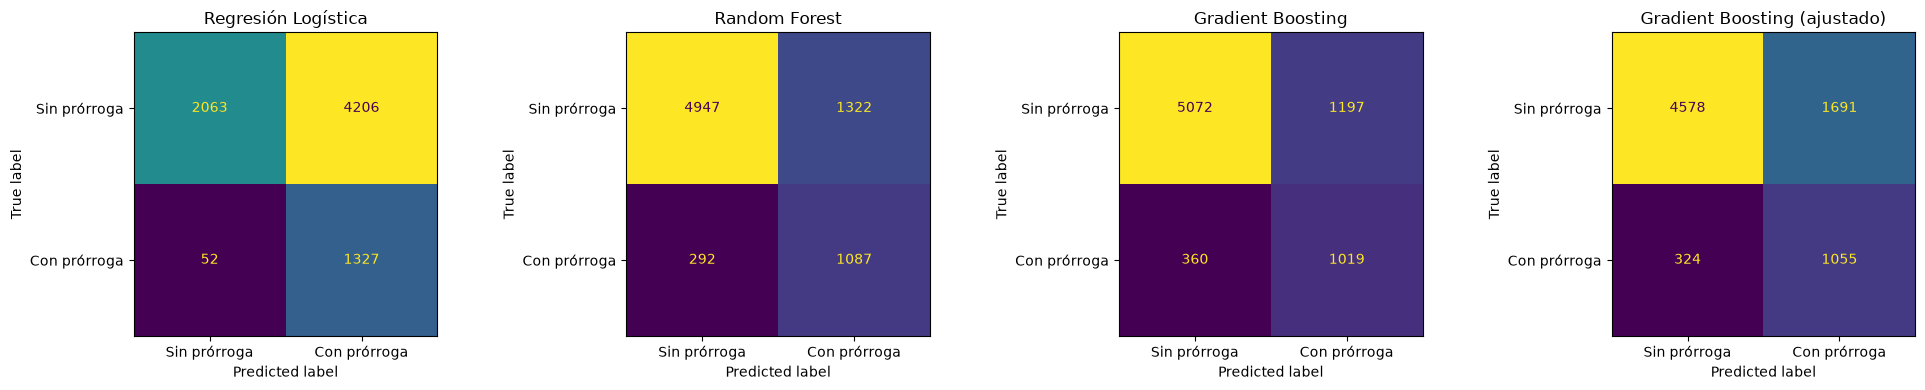

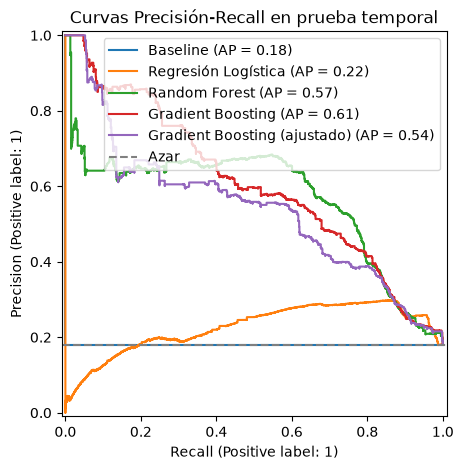

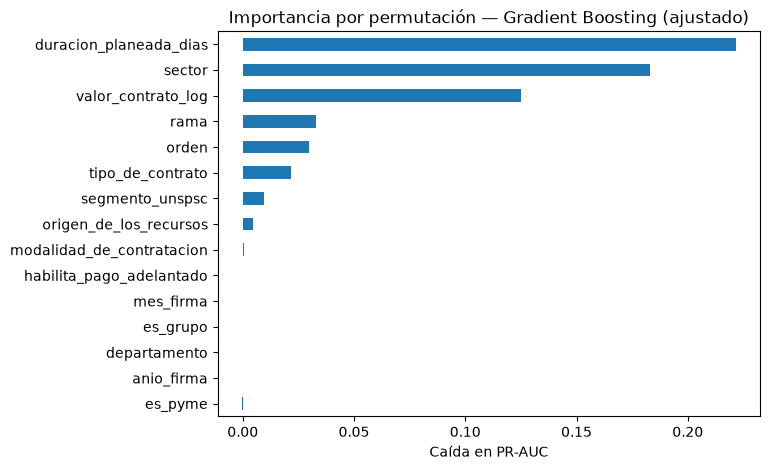

,contratos,tasa_real_prorroga,falsos_positivos,falsos_negativos
modalidad_de_contratacion,,,,
Contratación directa,6510,0.200,1496,283
Contratación régimen especial,447,0.020,29,8
Mínima cuantía,419,0.088,78,17
Contratación régimen especial (con ofertas),82,0.073,7,6
Contratación Directa (con ofertas),67,0.075,19,3
Selección Abreviada de Menor Cuantía,64,0.125,31,4
Selección abreviada subasta inversa,21,0.095,8,0
Licitación pública,16,0.188,10,2
Concurso de méritos abierto,10,0.300,6,1


In [35]:
# Tabla comparativa de métricas en el conjunto de prueba temporal + matrices de confusión y curvas PR
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
from observatorio.ml.evaluation import (
    analizar_errores_por_modalidad,
    calcular_importancia_variables,
    generar_tabla_comparativa_prueba,
)

# 1. Métricas en prueba temporal (datos no vistos durante el entrenamiento)
df_metricas = generar_tabla_comparativa_prueba(modelos, X_test, y_test, resultados_cv)
display(df_metricas)
print(f"Modelo seleccionado (mejor PR-AUC en validación cruzada): {nombre_final}")

# 2. Matrices de confusión (umbral 0.5) de los modelos con aprendizaje
nombres_graficar = [n for n in modelos if n != "Baseline"]
fig, axes = plt.subplots(1, len(nombres_graficar), figsize=(5 * len(nombres_graficar), 4))
for ax, nombre in zip(axes, nombres_graficar):
    ConfusionMatrixDisplay.from_estimator(
        modelos[nombre], X_test, y_test, ax=ax, colorbar=False,
        display_labels=["Sin prórroga", "Con prórroga"]
    )
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

# 3. Curvas Precisión-Recall (frente al azar = prevalencia)
fig, ax = plt.subplots(figsize=(7, 5))
for nombre, m in modelos.items():
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, ax=ax, name=nombre)
ax.axhline(y_test.mean(), linestyle="--", color="gray", label="Azar")
ax.set_title("Curvas Precisión-Recall en prueba temporal")
ax.legend()
plt.show()

# 4. Importancia por permutación
serie_imp = calcular_importancia_variables(modelo_final, X_test, y_test)
serie_imp.sort_values().plot.barh(figsize=(7, 5), title=f"Importancia por permutación — {nombre_final}")
plt.xlabel("Caída en PR-AUC")
plt.show()

# 5. Análisis de errores por modalidad de contratación
df_errores = analizar_errores_por_modalidad(modelo_final, df_test, X_test, y_test)
display(df_errores)

---
# PARTE 4: Del Análisis a la Aplicación Interactiva

## 4.1 Empaquetado del Modelo para Consulta en Tiempo Real
Exportamos el flujo completo del modelo ganador en un único archivo listo para producción (`pipeline_prorrogas.joblib`) y comprobamos que la aplicación web pueda cargarlo y generar estimaciones en una fracción de segundo.

In [36]:
# Guardar el artefacto del modelo con joblib.dump() y sus metadatos en JSON
import time
from observatorio.config import MODEL_ARTIFACT_PATH, MODEL_METADATA_PATH
from observatorio.ml.evaluation import guardar_artefacto_y_metadatos
from observatorio.ml.inference import cargar_modelo_prorrogas, predecir_riesgo_prorroga

# 1. Exportar pipeline completo y metadatos JSON auditables
metadatos = guardar_artefacto_y_metadatos(
    modelo=modelo_final,
    nombre_modelo=nombre_final,
    df_train=df_train,
    df_test=df_test,
    df_metricas=df_metricas,
)
print(f"✅ Modelo guardado en   : {MODEL_ARTIFACT_PATH}")
print(f"✅ Metadatos guardados en: {MODEL_METADATA_PATH}")

# 2. Verificación de carga en frío e inferencia unitaria (< 2 segundos, Métricas ML)
modelo_cargado = cargar_modelo_prorrogas()
contrato_ejemplo = X_test.iloc[0].to_dict()

t0 = time.perf_counter()
resultado = predecir_riesgo_prorroga(modelo_cargado, contrato_ejemplo)
latencia_ms = (time.perf_counter() - t0) * 1000

prob_memoria = modelo_final.predict_proba(X_test.iloc[[0]])[0, 1]
print(f"\nPredicción contrato ejemplo: {resultado}")
print(f"Tiempo de respuesta        : {latencia_ms:.1f} ms (requisito < 2000 ms)")
print(f"¿Coincide con memoria?     : {np.isclose(prob_memoria, resultado['probabilidad_prorroga'], atol=1e-4)}")

✅ Modelo guardado en   : /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/models/pipeline_prorrogas.joblib
✅ Metadatos guardados en: /Volumes/Content/Proyects/IA (Artificial Inteligen)/observatorio_secop_ii_desarrollo/models/model_metadata.json

Predicción contrato ejemplo: {'probabilidad_prorroga': 0.0189, 'nivel_riesgo': 'Bajo'}
Tiempo de respuesta        : 34.5 ms (requisito < 2000 ms)
¿Coincide con memoria?     : True


## 4.2 Transparencia, Alcance y Límites del Modelo
Para cerrar el flujo de desarrollo, dejamos documentadas las condiciones con las que fue entrenado el modelo, para qué sirve y cuáles son sus límites:
- **Para qué sirve:** Funciona como un filtro temprano para que periodistas, veedurías y equipos de auditoría decidan qué contratos revisar primero entre miles de procesos firmados.
- **Qué no debe hacerse con él:** No es un detector de corrupción ni un veredicto sobre la gestión de un contratista o entidad pública.
- **Limitaciones naturales:** Los datos tabulares de SECOP II resumen el contrato pero no contienen el texto detallado de los estudios previos ni las actas adjuntas, por lo que toda revisión debe culminar en el expediente electrónico original.